# Benchmark STGCN — occupation à +15 minutes sur PEMS08

STGCN combine des convolutions temporelles et une propagation sur le graphe pour prévoir **occupy(t+3)** sur **170 capteurs simultanément**. Les entrées sont **flow, occupy, speed**, pendant **12 timesteps** (12 intervalles de 5 minutes ; 55 minutes entre les horodatages extrêmes).

Ce notebook n’exécute aucun entraînement XGBoost, LSTM ou PatchTST. Il recharge leurs résultats sauvegardés et reprend les périodes du notebook 02. Le test n’est évalué qu’après sélection des poids sur validation.

Il s’agit d’une version légère inspirée du [STGCN de Yu et al.](https://arxiv.org/abs/1709.04875) : un bloc TemporalConv–GraphConv–TemporalConv, une convolution GCN du premier ordre et une tête de régression partagée entre nœuds. Ce n’est pas une reproduction exacte de la convolution Chebyshev du modèle original.

## Hypothèse de mapping et limite méthodologique

Les vrais fichiers PEMS08 sont ceux conservés dans `data/source/pems08/`, provenant du dépôt des auteurs ASTGCN. Le tenseur possède la clé `data`, les axes **temps × capteurs × variables** et l’ordre **flow, occupy, speed**, confirmés par les mesures.

**Nous utilisons explicitement l’hypothèse `location = index du capteur NPZ`.** Elle est cohérente avec les 170 séries du CSV et le chargeur du graphe des auteurs. Toutefois, les groupes **[48,61,80,121,122,123,141,142]**, **[50,51,74,75,90,91,115,131]**, **[55,70,73,81,83,84,159]**, **[62,109]** ont des séries intégralement identiques. Leurs identités exactes ne peuvent pas être prouvées par les valeurs seules. L’hypothèse est autorisée pour ce benchmark exploratoire, **sans création d’un faux manifeste ni déclaration de mapping pleinement authentifié**.

Cette incertitude doit accompagner les résultats STGCN. Une preuve du code d’export initial serait nécessaire pour la lever ; les données identiques ne permettent pas un test de sensibilité qui départagerait ces permutations.

In [1]:
# Charger les dépendances et les fichiers de référence, sans exécuter les modèles précédents.
from pathlib import Path
from time import perf_counter
import copy
import csv
import gc
import hashlib
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

racine = Path.cwd()
if not (racine / "data/raw/traffic_dataset.csv").is_file():
    racine = racine.parent
dossier_resultats = racine / "results/model_benchmark"
benchmark_path = dossier_resultats / "benchmark_results.csv"
benchmark_avant = pd.read_csv(benchmark_path, float_precision="round_trip")
assert {"XGBoost Regressor", "LSTM", "PatchTST"}.issubset(set(benchmark_avant.model))
provenance_path = racine / "data/source/pems08/validated_provenance.json"
provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
source_folder = racine / "data/source/pems08" / provenance["commit"]
source_npz = source_folder / "pems08.npz"
source_distance = source_folder / "distance.csv"
def empreinte(chemin):
    # Vérifier les sources locales par rapport aux empreintes de leur téléchargement.
    with chemin.open("rb") as flux:
        return hashlib.file_digest(flux, "sha256").hexdigest()
assert provenance["dataset"] == "PEMS08"
assert empreinte(source_npz) == provenance["npz_sha256"]
assert empreinte(source_distance) == provenance["distance_sha256"]
with np.load(source_npz, allow_pickle=False) as archive:
    assert archive.files == ["data"]
    mesures = archive["data"].copy()
assert mesures.shape == (17856, 170, 3) and np.isfinite(mesures).all()
stgcn_features = ["flow", "occupy", "speed"]
stgcn_target = "target_occupy_t15"
stgcn_horizon = 3
stgcn_history_length = 12
stgcn_mapping_assumption = "location=index_NPZ ; identité non prouvée pour les 25 capteurs aux séries identiques"
stgcn_seed = 42
torch.manual_seed(stgcn_seed)
np.random.seed(stgcn_seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
stgcn_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if stgcn_device.type == "cuda":
    torch.cuda.manual_seed_all(stgcn_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
print("NPZ :", mesures.shape, "| matériel :", stgcn_device, "| source :", provenance["source_url"])
print("Hypothèse de mapping :", stgcn_mapping_assumption)

NPZ : (17856, 170, 3) | matériel : cpu | source : https://github.com/Davidham3/ASTGCN-2019-mxnet/tree/d5d40645fa45471f2b473fc49a29ec3f0a993c6d/data/PEMS08
Hypothèse de mapping : location=index_NPZ ; identité non prouvée pour les 25 capteurs aux séries identiques


## Graphe pondéré, symétrisation et normalisation GCN

Les 295 lignes du fichier comprennent des doublons : on conserve les **arêtes uniques** après vérification qu’elles portent la même distance. Le noyau est **wᵢⱼ = exp(−dᵢⱼ²/σ²)**, avec σ égal à l’écart-type des distances uniques (ddof=0). Aucune distance n’est inventée et aucun seuil supplémentaire n’est choisi sur les scores. L’unité du fichier n’est pas présumée ; cette pondération est invariante à une conversion uniforme d’unité.

Le fichier garde ses orientations dans W. Pour cette version GCN, on choisit un **support non dirigé A = maximum(W, Wᵀ)** : chaque relation publiée devient une relation utilisable dans les deux sens. C’est un choix de modélisation, pas une preuve de bidirectionnalité physique. Aucune relation n’est ajoutée entre capteurs aux IDs consécutifs.

On ajoute ensuite **I** pour garder l’information de chaque nœud et on calcule **S = D⁻¹ᐟ²(A+I)D⁻¹ᐟ²**, selon la normalisation [GCN de Kipf et Welling](https://arxiv.org/abs/1609.02907). Les statistiques topologiques sont calculées **avant les self-loops**, qui masqueraient les nœuds isolés. Les poids et l’agrégation spatiale sont conservés en float64 pour éviter le sous-flux des poids gaussiens très petits ; les paramètres du réseau sont en float32.

In [2]:
# Construire le support à partir des seules arêtes publiées.
edges_raw = pd.read_csv(source_distance)
assert list(edges_raw.columns) == ["from", "to", "cost"]
assert edges_raw.shape == (295, 3)
assert np.isfinite(edges_raw.to_numpy()).all()
assert (edges_raw[["from", "to"]] % 1 == 0).all().all()
assert (edges_raw.cost >= 0).all()
assert edges_raw.groupby(["from", "to"]).cost.nunique().le(1).all()
edges = edges_raw.drop_duplicates(["from", "to"]).copy()
assert len(edges) == 277
ids = set(edges["from"]) | set(edges["to"])
assert ids == set(range(170))
sigma = float(edges.cost.to_numpy(dtype="float64").std(ddof=0))
assert np.isfinite(sigma) and sigma > 0
weights = np.exp(-np.square(edges.cost.to_numpy(dtype="float64") / sigma))
assert np.isfinite(weights).all() and (weights > 0).all()
W = np.zeros((170, 170), dtype="float64")
W[edges["from"].to_numpy(dtype="int64"), edges["to"].to_numpy(dtype="int64")] = weights
A = np.maximum(W, W.T)
assert A.shape == (170, 170) and np.isfinite(A).all()
assert np.array_equal(A, A.T)
support_sans_boucles = A > 0
np.fill_diagonal(support_sans_boucles, False)
degrees = support_sans_boucles.sum(axis=1)
isolated_nodes = np.flatnonzero(degrees == 0).tolist()
A_tilde = A + np.eye(170, dtype="float64")
D = A_tilde.sum(axis=1)
assert (D > 0).all()
S = A_tilde / np.sqrt(D[:, None] * D[None, :])
assert np.isfinite(S).all() and np.allclose(S, S.T, rtol=1e-14, atol=1e-14)
graph_stats = {
    "shape": list(A.shape), "sigma_unique_distances": sigma, "raw_rows": len(edges_raw),
    "unique_directed_edges": len(edges), "undirected_edges_without_loops": int(np.triu(support_sans_boucles, 1).sum()),
    "degree_mean": float(degrees.mean()), "degree_min": int(degrees.min()), "degree_max": int(degrees.max()),
    "isolated_nodes_before_loops": isolated_nodes, "symmetric": bool(np.array_equal(A, A.T)),
    "normalized_symmetric": bool(np.allclose(S, S.T)), "nan": int(np.isnan(S).sum()),
    "minimum_positive_weight": float(A[A > 0].min()), "self_loop_strategy": "A+I",
    "mapping_status": "hypothèse documentée pour les groupes indiscernables"
}
display(pd.DataFrame([graph_stats]))
print("Support original dirigé symétrique :", np.array_equal(W > 0, W.T > 0))
print("Capteurs isolés avant self-loops :", isolated_nodes)

,shape,sigma_unique_distances,raw_rows,unique_directed_edges,undirected_edges_without_loops,degree_mean,degree_min,degree_max,isolated_nodes_before_loops,symmetric,normalized_symmetric,nan,minimum_positive_weight,self_loop_strategy,mapping_status
0,"[170, 170]",217.576772,295,277,274,3.223529,1,9,[],True,True,0,4.355619e-99,A+I,hypothèse documentée pour les groupes indiscer...


Support original dirigé symétrique : False
Capteurs isolés avant self-loops : []


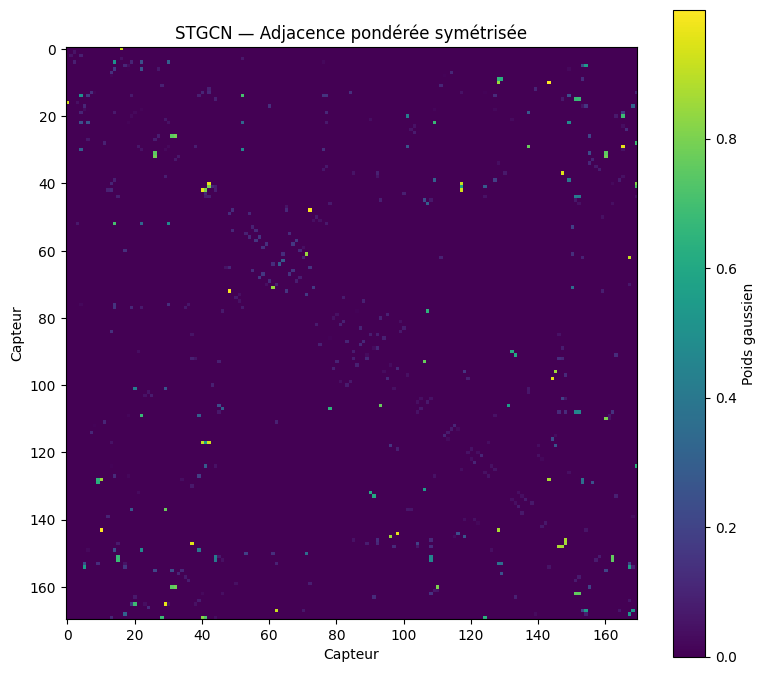

In [3]:
# Afficher le graphe pondéré symétrisé, avant l’ajout des self-loops.
plt.figure(figsize=(8, 7))
plt.imshow(A, cmap="viridis", interpolation="nearest")
plt.colorbar(label="Poids gaussien")
plt.xlabel("Capteur")
plt.ylabel("Capteur")
plt.title("STGCN — Adjacence pondérée symétrisée")
plt.tight_layout()
plt.savefig(dossier_resultats / 'stgcn_adjacency_heatmap.png', dpi=150, bbox_inches="tight")
plt.show()

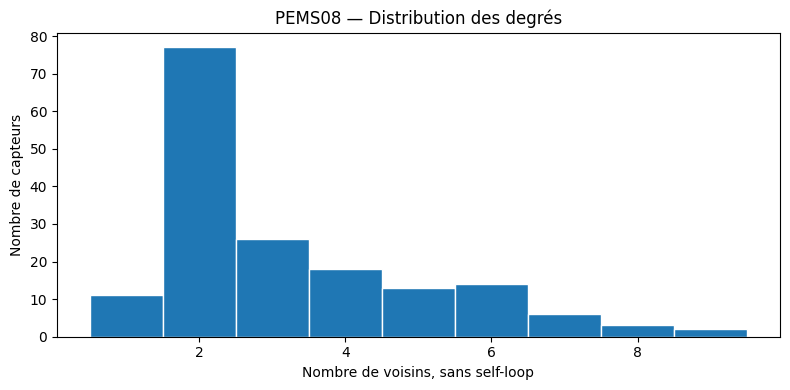

In [4]:
# Décrire les degrés topologiques sans les boucles de normalisation.
plt.figure(figsize=(8, 4))
plt.hist(degrees, bins=np.arange(degrees.min() - 0.5, degrees.max() + 1.5), edgecolor="white")
plt.xlabel("Nombre de voisins, sans self-loop")
plt.ylabel("Nombre de capteurs")
plt.title("PEMS08 — Distribution des degrés")
plt.tight_layout()
plt.savefig(dossier_resultats / 'stgcn_degree_distribution.png', dpi=150, bbox_inches="tight")
plt.show()

## Réutiliser exactement le split temporel existant

Nous réexécutons **uniquement le notebook 02**, qui prépare les features et cibles et ne contient aucun entraînement. Ses frontières 70/15/15 sont calculées après retrait des bords sans historique/cible, puis les cibles qui traverseraient train/validation ou validation/test sont purgées. Nous n’appliquons pas un nouveau split sur les 17 856 points bruts.

Les fenêtres STGCN se terminent aux mêmes timesteps que les observations des benchmarks. Les 12 mesures passées sont disponibles pour toutes ces lignes : **aucune observation test n’est retirée**. Une fenêtre représente tous les capteurs au même instant ; elle ne confond pas leurs axes. Train, validation et test restent chronologiques et les lots train ne sont pas mélangés.

In [5]:
# Charger uniquement la préparation existante, jamais le notebook 03.
get_ipython().run_line_magic("run", str(racine / "notebooks/02_feature_engineering.ipynb"))
assert horizon == stgcn_horizon
assert train.timestep.max() + horizon < validation.timestep.min()
assert validation.timestep.max() + horizon < test.timestep.min()

# Garder des versions compactes, et libérer les grands tableaux intermédiaires de préparation.
colonnes_utiles = ["location", "timestep"] + stgcn_features + [stgcn_target]
train = train[colonnes_utiles].copy()
validation = validation[colonnes_utiles].copy()
test = test[colonnes_utiles].copy()
for nom in ["df", "df_features", "ensembles", "exemples", "ensemble", "ecarts", "timestep_cible",
            "position_capteur", "taille_capteur", "lignes_invalides", "bords_attendus"]:
    globals().pop(nom, None)
gc.collect()

def fins_stgcn(ensemble):
    # Associer chaque timestep aux 170 nœuds, avec vérification des mesures et cibles du split.
    timesteps = np.sort(ensemble.timestep.unique())
    assert ensemble.groupby("timestep").location.nunique().eq(170).all()
    assert not ensemble.duplicated(["timestep", "location"]).any()
    assert len(ensemble) == len(timesteps) * 170
    fins = timesteps.astype("int64") - 1
    assert np.all(fins - stgcn_history_length + 1 >= 0)
    assert np.all(fins + stgcn_horizon < len(mesures))
    tri = ensemble.sort_values(["timestep", "location"])
    assert np.array_equal(tri.location.to_numpy().reshape(-1, 170)[0], np.arange(170))
    np.testing.assert_allclose(mesures[fins].reshape(-1, 3), tri[stgcn_features].to_numpy(), rtol=1e-5, atol=1e-6)
    np.testing.assert_allclose(mesures[fins + 3, :, 1].ravel(), tri[stgcn_target].to_numpy(), rtol=1e-5, atol=1e-6)
    return torch.from_numpy(fins.copy())

stgcn_train_ends = fins_stgcn(train)
stgcn_val_ends = fins_stgcn(validation)
stgcn_test_ends = fins_stgcn(test)
reference_lstm = benchmark_avant.loc[benchmark_avant.model.eq("LSTM")].iloc[0]
assert [len(train), len(validation), len(test)] == [int(reference_lstm[k]) for k in ["n_train", "n_validation", "n_test"]]
display(pd.DataFrame([{"ensemble": nom, "premier_timestep": frame.timestep.min(),
    "dernier_timestep": frame.timestep.max(), "fenêtres_conjointes": len(frame) // 170, "observations_capteurs": len(frame)}
    for nom, frame in [("train", train), ("validation", validation), ("test", test)]]))
print("Ordre des mesures conservé :", stgcn_features)

Shape du dataset source : (3035520, 5)


Nombre de capteurs : 170


Shape avant nettoyage : (3035520, 37)
Shape après nettoyage : (3032970, 37)
Lignes supprimées : 2550
NaN restants par colonne :


timestep                  0
location                  0
flow                      0
occupy                    0
speed                     0
day_index                 0
slot_in_day               0
hour                      0
minute                    0
time_label                0
flow_lag_1                0
flow_lag_2                0
flow_lag_3                0
flow_lag_6                0
flow_lag_12               0
speed_lag_1               0
speed_lag_2               0
speed_lag_3               0
speed_lag_6               0
speed_lag_12              0
occupy_lag_1              0
occupy_lag_2              0
occupy_lag_3              0
occupy_lag_6              0
occupy_lag_12             0
flow_rolling_mean_3       0
flow_rolling_mean_6       0
flow_rolling_mean_12      0
speed_rolling_mean_3      0
speed_rolling_mean_6      0
speed_rolling_mean_12     0
occupy_rolling_mean_3     0
occupy_rolling_mean_6     0
occupy_rolling_mean_12    0
target_flow_t15           0
target_speed_t15    

Timesteps disponibles : 17841
Répartition avant purge : 12488 2676 2677
Début de validation : 12501
Début de test : 15177


Lignes purgées à la fin de train : 510
Lignes purgées à la fin de validation : 510
            Timestep minimum  Timestep maximum  Timesteps distincts  Nombre de lignes  Nombre de capteurs
Ensemble                                                                                                 
Train                     13             12497                12485           2122450                 170
Validation             12501             15173                 2673            454410                 170
Test                   15177             17853                 2677            455090                 170


,ensemble,premier_timestep,dernier_timestep,fenêtres_conjointes,observations_capteurs
0,train,13,12497,12485,2122450
1,validation,12501,15173,2673,454410
2,test,15177,17853,2677,455090


Ordre des mesures conservé : ['flow', 'occupy', 'speed']


## Normalisation train et construction des lots

StandardScaler est ajusté uniquement sur les mesures des lignes de **train** (trois variables, tous les capteurs). Un second scaler standardise les cibles train à t+3. Validation et test n’interviennent dans aucun ajustement. Les mesures de bord exclues peuvent servir d’historique, transformé avec ces statistiques train.

Entrée conceptuelle **(batch, 12, 170, 3)** ; cible **(batch, 170)**. Les séquences sont assemblées à la demande avec les indices **t−11..t**, jamais avec t+1 ou au-delà. L’accès aux données test pour les assertions précédentes contrôle uniquement l’alignement du dataset, pas la sélection du modèle.

In [6]:
# Ajuster les deux scalers exclusivement sur les lignes et les cibles de train.
stgcn_scaler_X = StandardScaler().fit(train[stgcn_features].to_numpy())
stgcn_scaler_y = StandardScaler().fit(train[[stgcn_target]].to_numpy())
stgcn_base = torch.from_numpy(stgcn_scaler_X.transform(mesures.reshape(-1, 3)).reshape(mesures.shape).astype("float32"))
stgcn_offsets = torch.arange(-stgcn_history_length + 1, 1)
def cibles_stgcn(fins):
    # Normaliser avec le scaler train déjà ajusté, sans recalcul de statistiques.
    valeurs = mesures[fins.numpy() + 3, :, 1]
    return torch.from_numpy(stgcn_scaler_y.transform(valeurs.reshape(-1, 1)).reshape(valeurs.shape).astype("float32"))
stgcn_y_train = cibles_stgcn(stgcn_train_ends)
stgcn_y_val = cibles_stgcn(stgcn_val_ends)
stgcn_batch_size = 32
stgcn_max_epochs, stgcn_patience = 30, 5
stgcn_hidden_channels = 16

def lots_stgcn(fins, cibles=None):
    # Parcourir les fenêtres chronologiquement, sans shuffle global ni interne.
    for debut in range(0, len(fins), stgcn_batch_size):
        selection = fins[debut:debut + stgcn_batch_size]
        X = stgcn_base[selection[:, None] + stgcn_offsets].to(stgcn_device)
        y = None if cibles is None else cibles[debut:debut + stgcn_batch_size].to(stgcn_device)
        yield X, y

def synchroniser_stgcn():
    # Synchroniser le GPU avant de lire les chronomètres.
    if stgcn_device.type == "cuda":
        torch.cuda.synchronize()

premier_X, premier_y = next(lots_stgcn(stgcn_train_ends, stgcn_y_train))
assert tuple(premier_X.shape[1:]) == (12, 170, 3)
assert tuple(premier_y.shape[1:]) == (170,)
assert stgcn_offsets.max().item() == 0 and stgcn_offsets.min().item() == -11
print("Entrée :", tuple(premier_X.shape), "| cible :", tuple(premier_y.shape))
display(pd.DataFrame({"feature": stgcn_features, "moyenne_train": stgcn_scaler_X.mean_, "écart_type_train": stgcn_scaler_X.scale_}))

Entrée : (32, 12, 170, 3) | cible : (32, 170)


,feature,moyenne_train,écart_type_train
0,flow,230.335795,145.879290
1,occupy,0.064637,0.044949
2,speed,63.779774,6.560733


## Architecture PyTorch légère

Deux convolutions temporelles à portes (GLU, kernel 3, padding causal) entourent une propagation spatiale **S × H** et une projection des features. Les 16 canaux sont normalisés par LayerNorm puis dropout 0,1. La tête linéaire utilise **tous les 12 états temporels** de chaque nœud pour une sortie scalaire ; ses poids sont partagés entre capteurs.

Une connexion résiduelle de prévision part de l’occupation courante, exprimée dans l’échelle standardisée de la cible : le réseau apprend sa correction à +15 min. Il n’utilise aucune occupation future en entrée. La dernière projection démarre à zéro, ce qui initialise la prévision à la persistance présente, sans définir ou mesurer de métrique test supplémentaire.

In [7]:
class TemporalConv(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__()
        self.convolution = nn.Conv2d(input_channels, output_channels * 2, kernel_size=(3, 1))

    def forward(self, X):
        # Padding à gauche uniquement sur l’axe temporel ; aucun mélange entre nœuds.
        return F.glu(self.convolution(F.pad(X, (0, 0, 2, 0))), dim=1)

class GraphConv(nn.Module):
    def __init__(self, channels, adjacency):
        super().__init__()
        # Garder l’agrégation en double précision, y compris les très petits poids réels.
        self.register_buffer("support", torch.from_numpy(adjacency).to_sparse().coalesce())
        self.projection = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, X):
        batch, channels, times, nodes = X.shape
        dense = X.permute(3, 0, 2, 1).reshape(nodes, -1).double()
        propagated = torch.sparse.mm(self.support, dense).float()
        propagated = propagated.reshape(nodes, batch, times, channels).permute(1, 3, 2, 0)
        return F.relu(self.projection(propagated))

class STGCN(nn.Module):
    def __init__(self, support, channels=16):
        super().__init__()
        self.temporal1 = TemporalConv(3, channels)
        self.spatial = GraphConv(channels, support)
        self.temporal2 = TemporalConv(channels, channels)
        self.normalisation = nn.LayerNorm(channels)
        self.dropout = nn.Dropout(0.1)
        self.regression = nn.Linear(stgcn_history_length * channels, 1)
        nn.init.zeros_(self.regression.weight)
        nn.init.zeros_(self.regression.bias)
        self.register_buffer("occupy_mean_X", torch.tensor(float(stgcn_scaler_X.mean_[1]), dtype=torch.float32))
        self.register_buffer("occupy_scale_X", torch.tensor(float(stgcn_scaler_X.scale_[1]), dtype=torch.float32))
        self.register_buffer("target_mean", torch.tensor(float(stgcn_scaler_y.mean_[0]), dtype=torch.float32))
        self.register_buffer("target_scale", torch.tensor(float(stgcn_scaler_y.scale_[0]), dtype=torch.float32))

    def forward(self, X):
        # Préserver explicitement les axes batch, temps, nœuds et features.
        current_occupy = X[:, -1, :, 1] * self.occupy_scale_X + self.occupy_mean_X
        persistence = (current_occupy - self.target_mean) / self.target_scale
        H = X.permute(0, 3, 1, 2)
        H = self.temporal2(self.spatial(self.temporal1(H)))
        H = self.dropout(self.normalisation(H.permute(0, 2, 3, 1)))
        H = H.permute(0, 2, 1, 3).reshape(X.shape[0], 170, -1)
        return persistence + self.regression(H).squeeze(-1)

stgcn_model = STGCN(S, stgcn_hidden_channels).to(stgcn_device)
assert tuple(stgcn_model(premier_X).shape) == tuple(premier_y.shape)
stgcn_optimizer = torch.optim.AdamW(stgcn_model.parameters(), lr=1e-3, weight_decay=1e-4)
stgcn_loss = nn.MSELoss()
print("Paramètres entraînables :", sum(p.numel() for p in stgcn_model.parameters() if p.requires_grad))

Paramètres entraînables : 2385


## Entraînement et sélection exclusivement sur validation

MSE de la cible standardisée, AdamW (learning rate 0,001), maximum **30 époques** et patience **5**. Le meilleur état est choisi par la RMSE globale de validation dans l’échelle originale ; tous les capteurs y ont le même poids. Les meilleurs poids sont conservés en mémoire puis restaurés.

Le chronométrage inclut apprentissage et validations. Le test ne sert ni au choix de l’époque, ni à la pondération du graphe, ni à modifier les hyperparamètres après évaluation.

In [8]:
def rmse_validation_stgcn():
    # Accumuler la somme des carrés sur toutes les fenêtres et tous les capteurs.
    stgcn_model.eval()
    somme = 0.0
    with torch.inference_mode():
        for X, y in lots_stgcn(stgcn_val_ends, stgcn_y_val):
            somme += (stgcn_model(X).double() - y.double()).square().sum().item()
    return np.sqrt(somme / stgcn_y_val.numel()) * stgcn_scaler_y.scale_[0]

stgcn_best_rmse, stgcn_wait = float("inf"), 0
stgcn_best_state = None
stgcn_history_rows = []
synchroniser_stgcn()
stgcn_training_start = perf_counter()
for epoch in range(1, stgcn_max_epochs + 1):
    epoch_start = perf_counter()
    stgcn_model.train()
    somme_loss = 0.0
    for X, y in lots_stgcn(stgcn_train_ends, stgcn_y_train):
        stgcn_optimizer.zero_grad(set_to_none=True)
        loss = stgcn_loss(stgcn_model(X), y)
        assert torch.isfinite(loss).item(), "Perte non finie."
        loss.backward()
        nn.utils.clip_grad_norm_(stgcn_model.parameters(), max_norm=1.0)
        stgcn_optimizer.step()
        somme_loss += loss.item() * y.numel()
    validation_rmse = rmse_validation_stgcn()
    assert np.isfinite(validation_rmse)
    if validation_rmse < stgcn_best_rmse:
        stgcn_best_rmse, stgcn_best_epoch = validation_rmse, epoch
        stgcn_best_state = copy.deepcopy(stgcn_model.state_dict())
        stgcn_wait = 0
    else:
        stgcn_wait += 1
    synchroniser_stgcn()
    stgcn_history_rows.append({"epoch": epoch,
        "train_RMSE": np.sqrt(somme_loss / stgcn_y_train.numel()) * stgcn_scaler_y.scale_[0],
        "validation_RMSE": validation_rmse, "epoch_time_s": perf_counter() - epoch_start})
    print(f"Époque {epoch:02d} : validation RMSE={validation_rmse:.6f}, patience={stgcn_wait}/{stgcn_patience}", flush=True)
    if stgcn_wait >= stgcn_patience:
        print("Arrêt anticipé sur validation.", flush=True)
        break
assert stgcn_best_state is not None
stgcn_model.load_state_dict(stgcn_best_state)
stgcn_model.eval()
synchroniser_stgcn()
stgcn_training_time_s = perf_counter() - stgcn_training_start
stgcn_history = pd.DataFrame(stgcn_history_rows)
display(stgcn_history)
print("Meilleure époque :", stgcn_best_epoch, "| entraînement (s) :", stgcn_training_time_s)

Époque 01 : validation RMSE=0.016005, patience=0/5


Époque 02 : validation RMSE=0.015858, patience=0/5


Époque 03 : validation RMSE=0.015799, patience=0/5


Époque 04 : validation RMSE=0.015767, patience=0/5


Époque 05 : validation RMSE=0.015747, patience=0/5


Époque 06 : validation RMSE=0.015738, patience=0/5


... (22 outputs left out)

Époque 29 : validation RMSE=0.015629, patience=0/5


Époque 30 : validation RMSE=0.015618, patience=0/5


,epoch,train_RMSE,validation_RMSE,epoch_time_s
0,1,0.016085,0.016005,45.208436
1,2,0.015648,0.015858,42.528689
2,3,0.015539,0.015799,43.297061
3,4,0.015485,0.015767,43.405165
4,5,0.015458,0.015747,40.695580
5,6,0.015436,0.015738,41.300603
6,7,0.015423,0.015734,42.480115
7,8,0.015409,0.015717,55.273412
8,9,0.015395,0.015712,45.376116
9,10,0.015383,0.015705,57.180390


Meilleure époque : 30 | entraînement (s) : 1425.173466200009


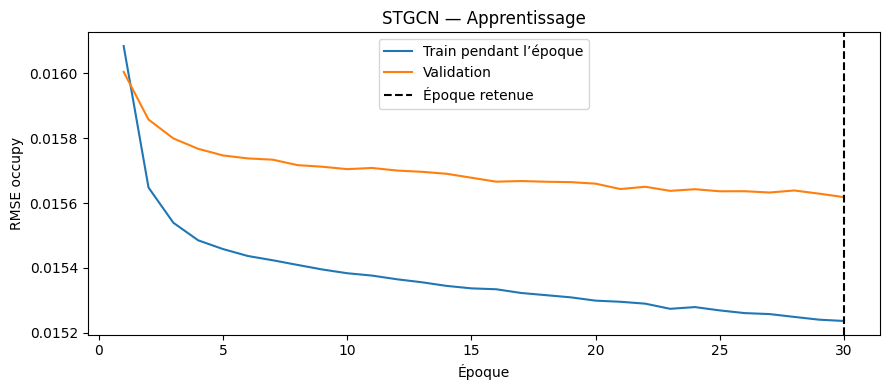

In [9]:
# Montrer les courbes train/validation sans consulter de métrique test.
plt.figure(figsize=(9, 4))
plt.plot(stgcn_history.epoch, stgcn_history.train_RMSE, label="Train pendant l’époque")
plt.plot(stgcn_history.epoch, stgcn_history.validation_RMSE, label="Validation")
plt.axvline(stgcn_best_epoch, color="black", linestyle="--", label="Époque retenue")
plt.xlabel("Époque")
plt.ylabel("RMSE occupy")
plt.title("STGCN — Apprentissage")
plt.legend()
plt.tight_layout()
plt.savefig(dossier_resultats / 'stgcn_learning_curve.png', dpi=150, bbox_inches="tight")
plt.show()

## Évaluation finale unique : scores globaux et par capteur

Le choix des poids est figé. L’échauffement utilise **validation**, puis une seule passe test produit toutes les prédictions, réutilisées pour les métriques et graphiques. Le temps d’inférence inclut assemblage des fenêtres, transferts, prédiction et reconversion de la cible ; il exclut chargement, graphe et fit des scalers. Il s’agit d’un débit par lots, pas d’une latence de requête.

Les métriques **globales** utilisent les mêmes 455 090 couples capteur/timestep que les benchmarks précédents. Les métriques **macro** sont la moyenne des scores calculés séparément par capteur ; la RMSE macro n’est pas identique à la RMSE globale. Le **R² par capteur est indéfini si sa cible test est constante** : il est alors noté NaN et exclu uniquement de la moyenne R² macro, avec le nombre de capteurs concernés indiqué. MAE et RMSE macro gardent les 170 capteurs.

In [10]:
def predire_stgcn(fins):
    # Prédire toutes les sorties du lot sans réordonner l’axe des capteurs.
    outputs = []
    with torch.inference_mode():
        for X, _ in lots_stgcn(fins):
            outputs.append(stgcn_model(X).cpu().numpy())
    outputs = np.concatenate(outputs, axis=0)
    return stgcn_scaler_y.inverse_transform(outputs.reshape(-1, 1)).reshape(outputs.shape)

# Échauffer sur validation puis effectuer la seule passe test.
_ = predire_stgcn(stgcn_val_ends[:stgcn_batch_size])
synchroniser_stgcn()
stgcn_inference_start = perf_counter()
stgcn_predictions = predire_stgcn(stgcn_test_ends)
synchroniser_stgcn()
stgcn_inference_time_s = perf_counter() - stgcn_inference_start
stgcn_actual = mesures[stgcn_test_ends.numpy() + 3, :, 1]
assert stgcn_predictions.shape == stgcn_actual.shape == (len(stgcn_test_ends), 170)
assert np.isfinite(stgcn_predictions).all()

# Retrouver exactement l’ordre des lignes test du benchmark tabulaire et du LSTM.
cles_prediction = pd.MultiIndex.from_product([stgcn_test_ends.numpy() + 1, np.arange(170)], names=["timestep", "location"])
ordre_test = cles_prediction.get_indexer(pd.MultiIndex.from_frame(test[["timestep", "location"]]))
assert (ordre_test >= 0).all() and len(np.unique(ordre_test)) == len(test)
stgcn_prediction_lignes = stgcn_predictions.ravel()[ordre_test]
stgcn_y_test_original = test[stgcn_target].to_numpy()
np.testing.assert_allclose(stgcn_actual.ravel()[ordre_test], stgcn_y_test_original, rtol=1e-5, atol=1e-6)
stgcn_global_mae = mean_absolute_error(stgcn_y_test_original, stgcn_prediction_lignes)
stgcn_global_rmse = float(np.sqrt(mean_squared_error(stgcn_y_test_original, stgcn_prediction_lignes)))
stgcn_global_r2 = r2_score(stgcn_y_test_original, stgcn_prediction_lignes)
rows = []
for node in range(170):
    real, predicted = stgcn_actual[:, node], stgcn_predictions[:, node]
    constant = bool(np.ptp(real) == 0)
    rows.append({"location": node, "n_test": len(real), "MAE": mean_absolute_error(real, predicted),
        "RMSE": float(np.sqrt(mean_squared_error(real, predicted))),
        "R2": np.nan if constant else r2_score(real, predicted), "constant_target": constant})
stgcn_per_sensor = pd.DataFrame(rows)
stgcn_metrics = pd.DataFrame([
    {"model": "STGCN", "aggregation": "global", "target": stgcn_target, "horizon_minutes": 15,
     "MAE": stgcn_global_mae, "RMSE": stgcn_global_rmse, "R2": stgcn_global_r2,
     "training_time_s": stgcn_training_time_s, "inference_time_s": stgcn_inference_time_s,
     "n_test": len(test), "n_nodes": 170, "n_R2_defined": int(stgcn_per_sensor.R2.notna().sum())},
    {"model": "STGCN", "aggregation": "macro_mean_per_sensor", "target": stgcn_target, "horizon_minutes": 15,
     "MAE": stgcn_per_sensor.MAE.mean(), "RMSE": stgcn_per_sensor.RMSE.mean(), "R2": stgcn_per_sensor.R2.mean(),
     "training_time_s": stgcn_training_time_s, "inference_time_s": stgcn_inference_time_s,
     "n_test": len(test), "n_nodes": 170, "n_R2_defined": int(stgcn_per_sensor.R2.notna().sum())},
])
display(stgcn_metrics)
print("Capteurs à cible test constante, R² individuel indéfini :", stgcn_per_sensor.loc[stgcn_per_sensor.constant_target, "location"].tolist())

,model,aggregation,target,horizon_minutes,MAE,RMSE,R2,training_time_s,inference_time_s,n_test,n_nodes,n_R2_defined
0,STGCN,global,target_occupy_t15,15,0.007355,0.017009,0.883074,1425.173466,2.671915,455090,170,170
1,STGCN,macro_mean_per_sensor,target_occupy_t15,15,0.007355,0.013555,0.853572,1425.173466,2.671915,455090,170,170


Capteurs à cible test constante, R² individuel indéfini : []


## Enregistrer STGCN en préservant les résultats existants

La ligne STGCN contient les métriques **globales**, comparables au tableau précédent. `n_test` compte les observations capteur/timestep et `n_test_windows` les fenêtres conjointes. L’hypothèse de mapping reste enregistrée avec les résultats et les poids.

L’export CSV reprend les champs des lignes des anciens modèles sous leur forme textuelle exacte afin de préserver leurs scores, temps et hyperparamètres. Aucune inférence des modèles existants n’est effectuée. Les graphes et poids sauvegardés sont des artifacts de ce benchmark sous hypothèse, pas une preuve officielle de mapping.

In [11]:
resultat_stgcn = {
    "model": "STGCN", "target": stgcn_target, "horizon_minutes": 15,
    "MAE": stgcn_global_mae, "RMSE": stgcn_global_rmse, "R2": stgcn_global_r2,
    "training_time_s": stgcn_training_time_s, "tuning_time_s": stgcn_training_time_s,
    "inference_time_s": stgcn_inference_time_s, "inference_us_per_row": stgcn_inference_time_s / len(test) * 1e6,
    "validation_RMSE": stgcn_best_rmse, "n_train": len(train), "n_validation": len(validation), "n_test": len(test),
    "n_features": 3, "sequence_length": 12, "best_epoch": stgcn_best_epoch, "epochs_trained": len(stgcn_history),
    "torch_version": torch.__version__, "device": str(stgcn_device), "n_jobs": torch.get_num_threads(),
    "n_nodes": 170, "n_test_windows": len(stgcn_test_ends), "mapping_assumption": stgcn_mapping_assumption,
    "hyperparameters": json.dumps({"architecture": "TemporalGLU-GraphGCN-TemporalGLU",
        "hidden_channels": 16, "temporal_kernel": 3, "num_st_blocks": 1, "dropout": 0.1,
        "learning_rate": 0.001, "weight_decay": 0.0001, "batch_size": stgcn_batch_size,
        "max_epochs": 30, "patience": 5, "graph": "gaussian-max-symmetric-with-self-loops",
        "sigma": sigma, "adjacency_normalization": "D^-1/2(A+I)D^-1/2", "threshold": None,
        "forecast_residual": "current_occupy", "train_shuffle": False}, sort_keys=True)
}
# Préserver tous les champs textuels des autres modèles lors de l’ajout de colonnes.
with benchmark_path.open(encoding="utf-8", newline="") as flux:
    reader = csv.DictReader(flux)
    colonnes_avant = list(reader.fieldnames)
    lignes_avant = list(reader)
anciennes_lignes = [ligne for ligne in lignes_avant if not (
    ligne["model"] == "STGCN" and ligne["target"] == stgcn_target and float(ligne["horizon_minutes"]) == 15)]
colonnes_export = colonnes_avant + [cle for cle in resultat_stgcn if cle not in colonnes_avant]
chemin_temporaire = benchmark_path.with_suffix(".csv.tmp")
with chemin_temporaire.open("w", encoding="utf-8", newline="") as flux:
    writer = csv.DictWriter(flux, fieldnames=colonnes_export)
    writer.writeheader()
    writer.writerows(anciennes_lignes)
    writer.writerow(resultat_stgcn)
os.replace(chemin_temporaire, benchmark_path)
with benchmark_path.open(encoding="utf-8", newline="") as flux:
    verification_lignes = list(csv.DictReader(flux))
assert all({cle: nouveau[cle] for cle in colonnes_avant} == ancien
    for ancien, nouveau in zip(anciennes_lignes, verification_lignes))
benchmark_results = pd.read_csv(benchmark_path, float_precision="round_trip")

# Sauvegarder les scores mesurés et les artifacts nécessaires à la reproduction.
stgcn_metrics.to_csv(dossier_resultats / "stgcn_metrics.csv", index=False)
stgcn_per_sensor.to_csv(dossier_resultats / "stgcn_per_sensor_metrics.csv", index=False)
stgcn_history.to_csv(dossier_resultats / "stgcn_training_history.csv", index=False)
np.save(dossier_resultats / "stgcn_adjacency.npy", A, allow_pickle=False)
(dossier_resultats / "stgcn_graph_stats.json").write_text(json.dumps(graph_stats, ensure_ascii=False, indent=2), encoding="utf-8")
np.savez_compressed(dossier_resultats / "stgcn_test_predictions.npz", predictions=stgcn_predictions,
    actual=stgcn_actual, input_timesteps=stgcn_test_ends.numpy() + 1, target_timesteps=stgcn_test_ends.numpy() + 4,
    sensor_ids=np.arange(170))
torch.save({"state_dict": {nom: poids.detach().cpu() for nom, poids in stgcn_best_state.items()},
    "features": stgcn_features, "target": stgcn_target, "feature_mean": stgcn_scaler_X.mean_.tolist(),
    "feature_scale": stgcn_scaler_X.scale_.tolist(), "target_mean": stgcn_scaler_y.mean_.tolist(),
    "target_scale": stgcn_scaler_y.scale_.tolist(), "sequence_length": 12, "horizon": 3,
    "hyperparameters": json.loads(resultat_stgcn["hyperparameters"]), "best_epoch": stgcn_best_epoch,
    "source_commit": provenance["commit"], "mapping_assumption": stgcn_mapping_assumption},
    dossier_resultats / "stgcn_best.pt")
print("Scores sauvegardés ; champs des modèles existants conservés à l’identique.")

Scores sauvegardés ; champs des modèles existants conservés à l’identique.


## Comparaison des quatre modèles et limites de fairness

Les cibles, horizon et observations test sont identiques. Cependant, **XGBoost** utilise des features tabulaires préparées (dont lags, moyennes et identifiant de capteur), **LSTM** et **PatchTST** utilisent des séquences indépendantes par capteur, et **STGCN** prédit les 170 nœuds conjointement avec information spatiale. PatchTST emploie aussi un historique plus long. Les performances ne mesurent donc pas le seul effet de l’architecture.

Les temps doivent être interprétés selon le matériel et le périmètre expliqué dans chaque notebook. Le temps STGCN par observation est divisé par le nombre de sorties capteur/timestep, pas par le nombre de fenêtres. L’incertitude de mapping et la symétrisation restent des limites de ce benchmark. Le classement utilise exclusivement les scores globaux non arrondis.

In [12]:
comparaison = benchmark_results.loc[benchmark_results.target.eq(stgcn_target) & benchmark_results.horizon_minutes.eq(15)
    & benchmark_results.model.isin(["XGBoost Regressor", "LSTM", "PatchTST", "STGCN"])].sort_values("RMSE", kind="stable").reset_index(drop=True)
assert len(comparaison) == 4 and comparaison.model.is_unique
assert comparaison.n_test.eq(len(test)).all()
renommage = {"model": "Model", "target": "Target", "horizon_minutes": "Horizon (min)",
    "MAE": "MAE", "RMSE": "RMSE", "R2": "R²", "training_time_s": "Training Time (s)", "inference_time_s": "Inference Time (s)"}
stgcn_summary = comparaison[list(renommage)].rename(columns=renommage)
stgcn_summary.insert(0, "Rank", comparaison.RMSE.rank(method="min").astype(int))
display(stgcn_summary.style.format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R²": "{:.4f}",
    "Training Time (s)": "{:.3f}", "Inference Time (s)": "{:.3f}"}))
stgcn_summary.to_csv(dossier_resultats / "stgcn_benchmark_summary.csv", index=False)

,Rank,Model,Target,Horizon (min),MAE,RMSE,R²,Training Time (s),Inference Time (s)
0,1,XGBoost Regressor,target_occupy_t15,15,0.00649,0.01644,0.8908,30.326,0.465
1,2,LSTM,target_occupy_t15,15,0.00709,0.01662,0.8883,174.499,0.764
2,3,PatchTST,target_occupy_t15,15,0.00717,0.01665,0.8880,2961.918,8.773
3,4,STGCN,target_occupy_t15,15,0.00735,0.01701,0.8831,1425.173,2.672


## Visualisation temporelle de trois capteurs

Les IDs **0, 10, 100** sont fixés avant l’évaluation, parmi les capteurs dont les séries sont distinguables. Les figures montrent leurs 288 premières observations test (une journée d’intervalles), avec l’axe au **timestep de la cible t+3**. Ils ne sont pas sélectionnés selon leur erreur ; les trois vues ne remplacent pas les scores globaux et par capteur.

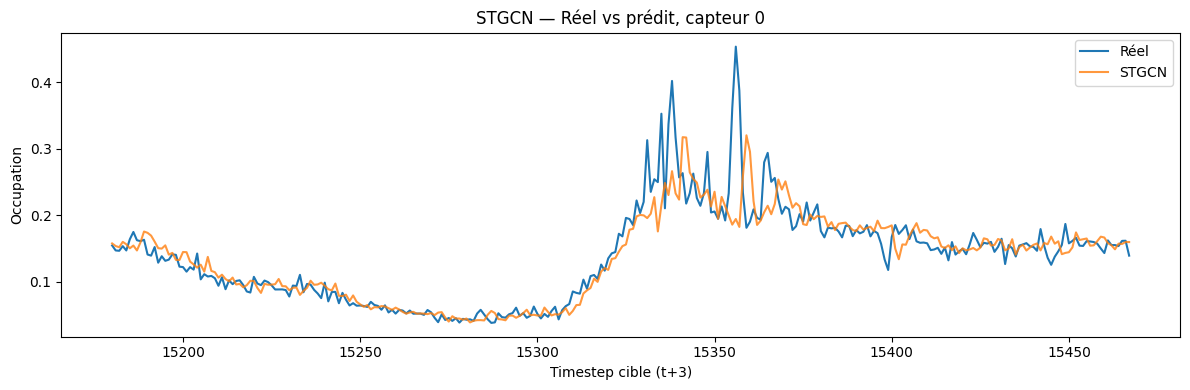

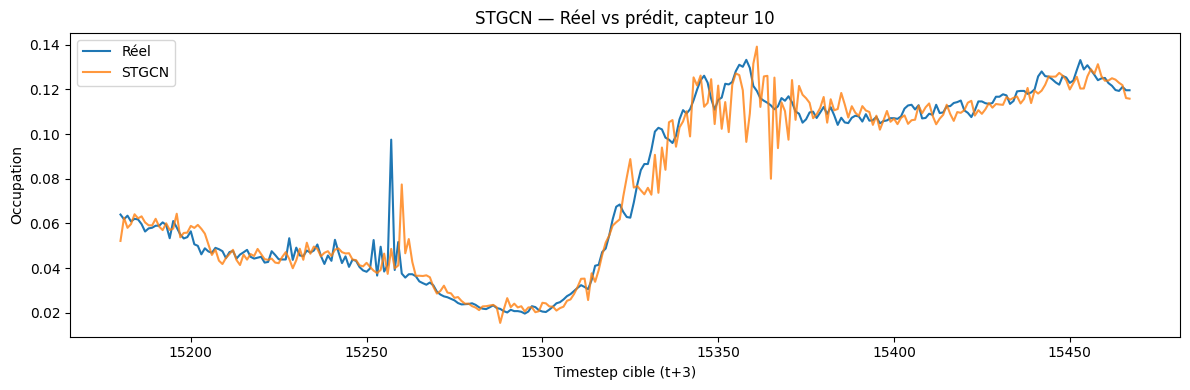

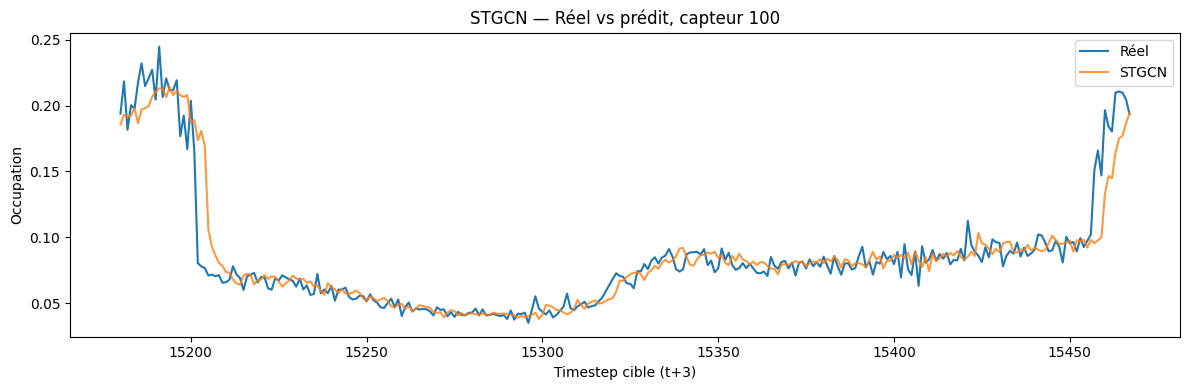

In [13]:
# Réutiliser les prédictions déjà calculées pour trois séries temporelles indépendantes.
for node in [0, 10, 100]:
    taille = min(288, len(stgcn_test_ends))
    abscisses = stgcn_test_ends.numpy()[:taille] + 4
    plt.figure(figsize=(12, 4))
    plt.plot(abscisses, stgcn_actual[:taille, node], label="Réel")
    plt.plot(abscisses, stgcn_predictions[:taille, node], label="STGCN", alpha=0.8)
    plt.xlabel("Timestep cible (t+3)")
    plt.ylabel("Occupation")
    plt.title(f"STGCN — Réel vs prédit, capteur {node}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(dossier_resultats / f"stgcn_actual_vs_predicted_sensor_{node}.png", dpi=150, bbox_inches="tight")
    plt.show()

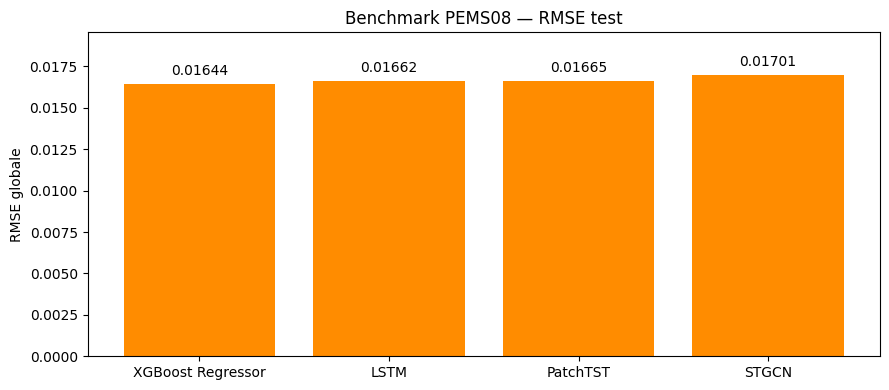

In [14]:
# Comparer les RMSE globales des quatre modèles sans nouvelle inférence.
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.bar(comparaison.model, comparaison.RMSE, color="darkorange")
ax.bar_label(barres, fmt="%.5f", padding=4)
ax.set_ylabel("RMSE globale")
ax.set_title("Benchmark PEMS08 — RMSE test")
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig(dossier_resultats / 'stgcn_models_rmse.png', dpi=150, bbox_inches="tight")
plt.show()

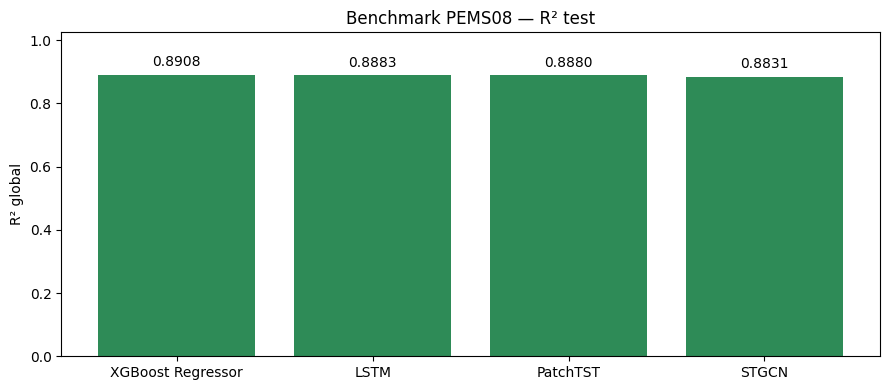

In [15]:
# Comparer les R² globaux sur une figure séparée, avec zéro comme référence.
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.bar(comparaison.model, comparaison.R2, color="seagreen")
ax.bar_label(barres, fmt="%.4f", padding=4)
ax.axhline(0, color="black", linewidth=0.7)
ax.set_ylabel("R² global")
ax.set_title("Benchmark PEMS08 — R² test")
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig(dossier_resultats / 'stgcn_models_r2.png', dpi=150, bbox_inches="tight")
plt.show()

## Interprétation automatique des résultats

La conclusion ci-dessous repose sur les métriques réellement obtenues après l’entraînement et la sélection par validation. Elle ne suppose pas que l’information spatiale améliorera les scores et ne déclenche aucun nouvel ajustement après le test.

In [16]:
# Générer l’interprétation uniquement à partir des métriques réelles.
gagnant_rmse = comparaison.loc[comparaison.RMSE.idxmin()]
gagnant_r2 = comparaison.loc[comparaison.R2.idxmax()]
plus_rapide = comparaison.loc[comparaison.training_time_s.idxmin()]
rang_stgcn = int(stgcn_summary.loc[stgcn_summary.Model.eq("STGCN"), "Rank"].iloc[0])
interpretation = (
    f"**STGCN : MAE={stgcn_global_mae:.6f}, RMSE={stgcn_global_rmse:.6f}, R²={stgcn_global_r2:.4f}**, "
    f"rang RMSE {rang_stgcn}/4 sur {len(test):,} observations test.\n\n"
    f"Meilleur selon RMSE : **{gagnant_rmse['model']}** ({gagnant_rmse['RMSE']:.6f}). "
    f"Meilleur selon R² : **{gagnant_r2['model']}** ({gagnant_r2['R2']:.4f}). "
    f"Entraînement le plus court : **{plus_rapide['model']}** ({plus_rapide['training_time_s']:.3f} s).\n\n"
    f"STGCN a demandé {stgcn_training_time_s:.3f} s d’entraînement et {stgcn_inference_time_s:.3f} s d’inférence, "
    f"avec sélection de l’époque {stgcn_best_epoch} sur validation. "
    f"Le R² macro est calculé sur {stgcn_per_sensor.R2.notna().sum()} capteurs à cible test non constante.\n\n"
    "Ces conclusions concernent cette configuration et ce test. Les entrées diffèrent entre architectures ; "
    "aucune ablation du graphe n’a été menée pour isoler son effet. "
    "Le mapping location=index NPZ reste une hypothèse documentée pour 25 capteurs indiscernables, "
    "et le support spatial a été symétrisé pour ce GCN."
)
display(Markdown(interpretation))
methodologie = "# Benchmark STGCN — méthode et résultats\n\n" + "\n\n".join(
    cell for cell in [
        "Sources : " + provenance["source_url"],
        "Hypothèse : " + stgcn_mapping_assumption,
        "Graphe : noyau gaussien sur distances uniques, symétrisation max(W,W.T), self-loops A+I, normalisation symétrique ; aucune relation basée sur les IDs consécutifs.",
        "Split : notebook 02 réutilisé, mêmes observations test que XGBoost/LSTM/PatchTST, fenêtres de 12 timesteps, horizon +3 (+15 min). Scalers ajustés sur train uniquement.",
        "Comparaison : XGBoost tabulaire, LSTM/PatchTST par capteur, STGCN conjoint/spatial ; périmètres d’inférence différents.",
        interpretation
    ])
(dossier_resultats / "stgcn_methodology.md").write_text(methodologie + "\n", encoding="utf-8")

**STGCN : MAE=0.007355, RMSE=0.017009, R²=0.8831**, rang RMSE 4/4 sur 455,090 observations test.

Meilleur selon RMSE : **XGBoost Regressor** (0.016440). Meilleur selon R² : **XGBoost Regressor** (0.8908). Entraînement le plus court : **XGBoost Regressor** (30.326 s).

STGCN a demandé 1425.173 s d’entraînement et 2.672 s d’inférence, avec sélection de l’époque 30 sur validation. Le R² macro est calculé sur 170 capteurs à cible test non constante.

Ces conclusions concernent cette configuration et ce test. Les entrées diffèrent entre architectures ; aucune ablation du graphe n’a été menée pour isoler son effet. Le mapping location=index NPZ reste une hypothèse documentée pour 25 capteurs indiscernables, et le support spatial a été symétrisé pour ce GCN.

1473